In [1]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/featured_data.csv", parse_dates=["StartDatetime"])
df = df.sort_values("StartDatetime").reset_index(drop=True)

cat_cols = ["ChargerCompany", "ChargerType", "Location", "TimeOfDay"]
num_cols = ["Hour", "Day", "Month", "DayOfWeek", "IsWeekend",
            "User_PrevSessions", "User_AvgPastDemand",
            "Charger_PrevSessions", "Charger_AvgPastDemand", "IsNewUser"]
X = df[cat_cols + num_cols]
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]

reg_pipe = joblib.load("../models/best_regression_model.pkl")   # LightGBM
prep = reg_pipe.named_steps["prep"]
model = reg_pipe.named_steps["model"]

feat_names = prep.get_feature_names_out()
feat_names = [n.split("__", 1)[1] for n in feat_names]

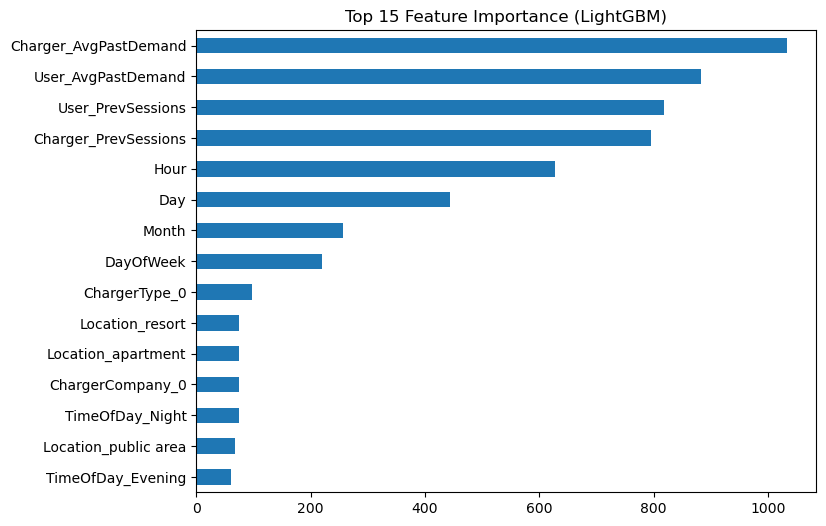

In [2]:
imp = pd.Series(model.feature_importances_, index=feat_names).sort_values(ascending=False)
imp.head(15).sort_values().plot.barh(figsize=(8, 6), title="Top 15 Feature Importance (LightGBM)")
plt.show()

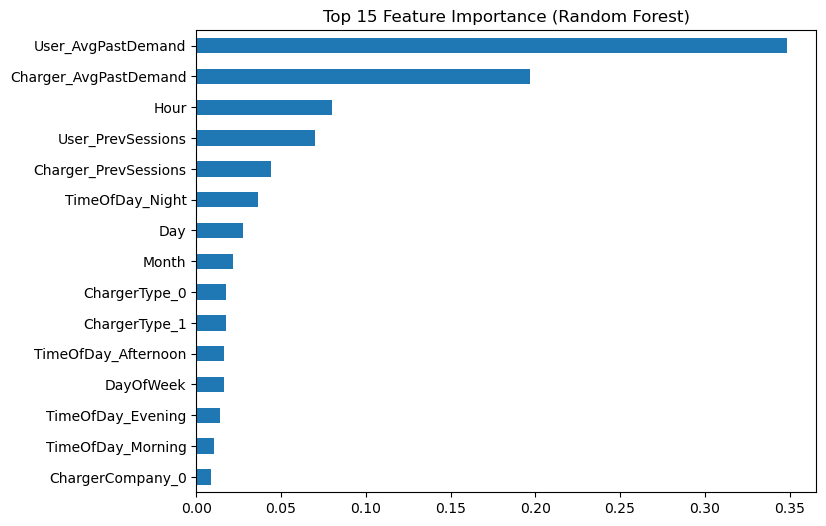

In [3]:
clf_pipe = joblib.load("../models/best_classification_model.pkl")
clf_imp = pd.Series(clf_pipe.named_steps["model"].feature_importances_,
                    index=feat_names).sort_values(ascending=False)
clf_imp.head(15).sort_values().plot.barh(figsize=(8, 6), title="Top 15 Feature Importance (Random Forest)")
plt.show()

In [4]:
import os
os.makedirs("../results", exist_ok=True)

imp.to_csv("../results/reg_feature_importance.csv", header=["importance"])
clf_imp.to_csv("../results/clf_feature_importance.csv", header=["importance"])
print("saved")

saved
